# 06 - Handwritten digit recognition with a neural network

A full pipeline: data -> from-scratch MLP (backprop, Adam, dropout, L2, early stopping) -> evaluation -> error analysis. Uses scikit-learn's bundled **8x8 digits** (1,797 images, instantly available offline); the last section shows the one-line change for the real 28x28 MNIST.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
import mlforge
from mlforge import visualization as viz
print("MLForge", mlforge.__version__)

MLForge 0.2.0


(1797, 64) pixels in [0,16]; classes: [0 1 2 3 4 5 6 7 8 9]


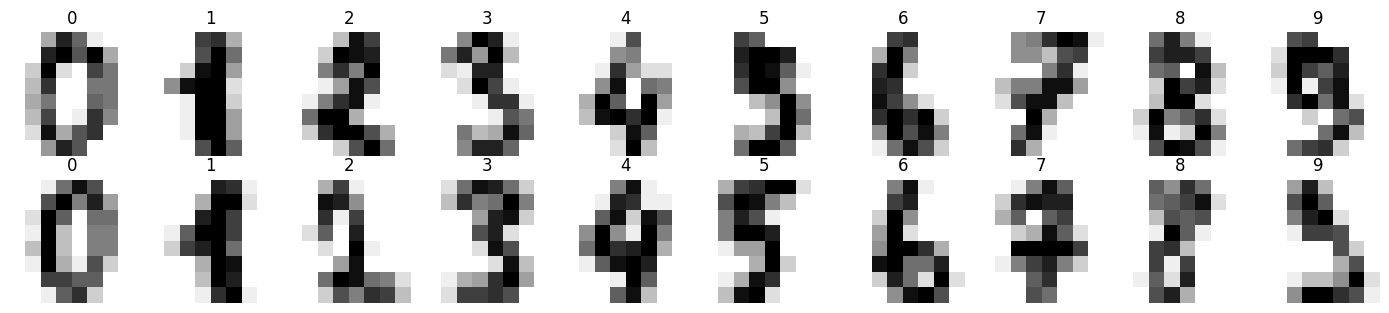

In [2]:
from sklearn.datasets import load_digits
d = load_digits(); X, y = d.data, d.target
print(X.shape, "pixels in [0,16]; classes:", np.unique(y))
fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for i, a in enumerate(ax.ravel()): a.imshow(X[i].reshape(8, 8), cmap="gray_r"); a.set_title(y[i]); a.axis("off")
plt.tight_layout()

In [3]:
from mlforge.preprocessing import train_test_split, StandardScaler
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=0, stratify=y)
sc = StandardScaler().fit(Xtr); Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)

## Train the network
`MLPClassifier` is built on the library's own `Dense` / `ReLU` / `Dropout` layers, softmax cross-entropy and Adam.

epochs run: 21 | train acc: 0.9978 | test acc: 0.9667
Sequential model
--------------------------------------------
 0 Dense        64 -> 128          8320 params
 1 ReLU                               0 params
 2 Dropout                            0 params
 3 Dense        128 -> 64          8256 params
 4 ReLU                               0 params
 5 Dropout                            0 params
 6 Dense        64 -> 10            650 params
--------------------------------------------
Total trainable parameters: 17226


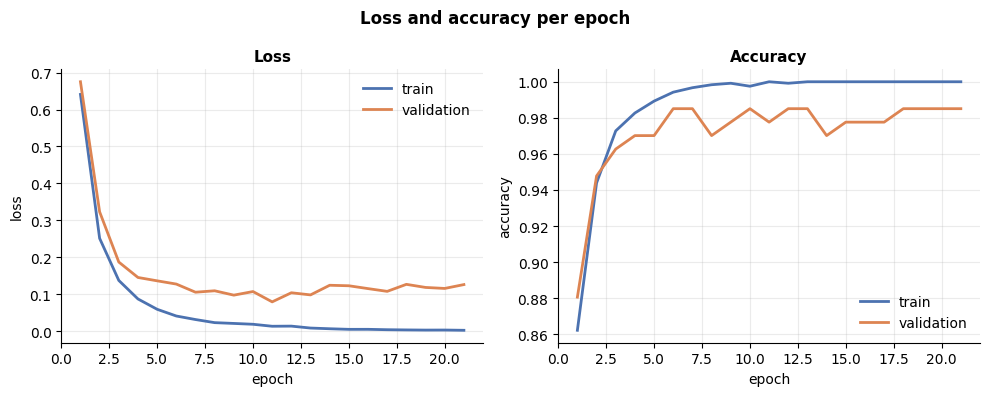

In [4]:
from mlforge.neural_network import MLPClassifier
mlp = MLPClassifier(hidden_sizes=(128, 64), activation="relu", optimizer="adam", learning_rate=0.002,
                    l2=1e-4, dropout=0.1, n_epochs=80, batch_size=64, early_stopping=True, patience=10, random_state=0).fit(Ztr, ytr)
print("epochs run:", mlp.n_epochs_run_, "| train acc:", round(mlp.score(Ztr, ytr), 4), "| test acc:", round(mlp.score(Zte, yte), 4))
print(mlp.model_.summary())
viz.plot_training_curves(mlp.history_, title="Loss and accuracy per epoch");

## Where does it go wrong?

              precision     recall   f1-score   support

           0       1.00       1.00       1.00        45
           1       0.94       0.98       0.96        46
           2       0.98       0.98       0.98        44
           3       0.96       0.93       0.95        46
           4       1.00       0.98       0.99        45
           5       0.92       1.00       0.96        46
           6       1.00       1.00       1.00        45
           7       0.98       0.98       0.98        45
           8       0.93       0.89       0.91        44
           9       0.98       0.93       0.95        45

    accuracy                             0.97       451
   macro avg       0.97       0.97       0.97       451
weighted avg       0.97       0.97       0.97       451



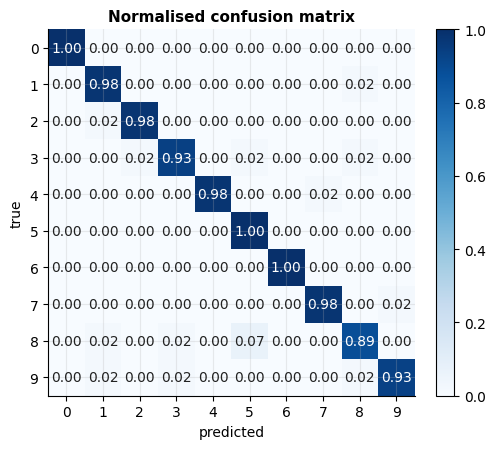

In [5]:
from mlforge.metrics import classification_report
pred = mlp.predict(Zte)
print(classification_report(yte, pred))
viz.plot_confusion_matrix(yte, pred, normalize="true", title="Normalised confusion matrix");

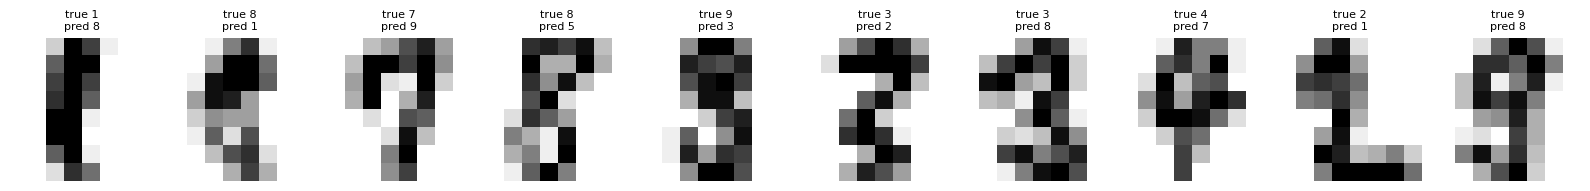

In [6]:
wrong = np.where(pred != yte)[0][:10]
fig, ax = plt.subplots(1, max(len(wrong), 1), figsize=(1.6 * max(len(wrong), 1), 2.2))
for a, i in zip(np.atleast_1d(ax), wrong): a.imshow(Xte[i].reshape(8, 8), cmap="gray_r"); a.set_title(f"true {yte[i]}\npred {pred[i]}", fontsize=8); a.axis("off")
plt.tight_layout()

## Does the optimizer matter? Same network, four optimizers
Plain SGD needs far more epochs than Adam / RMSProp at the same budget.

sgd       final train loss 0.0797  test acc 0.9579
momentum  final train loss 0.0129  test acc 0.9645


rmsprop   final train loss 0.0005  test acc 0.9690


adam      final train loss 0.0234  test acc 0.9712


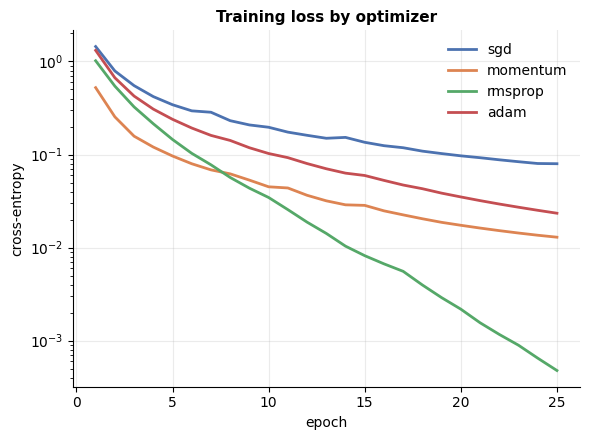

In [7]:
hist = {}
for opt, lr in [("sgd", 0.05), ("momentum", 0.02), ("rmsprop", 0.002), ("adam", 0.002)]:
    m = MLPClassifier((64,), optimizer=opt, learning_rate=lr, n_epochs=25, batch_size=64, random_state=0).fit(Ztr, ytr)
    hist[opt] = m.history_["loss"]; print(f"{opt:<9} final train loss {m.history_['loss'][-1]:.4f}  test acc {m.score(Zte, yte):.4f}")
viz.plot_learning_curve(hist, log_y=True, title="Training loss by optimizer", ylabel="cross-entropy");

## How does the MLP compare with simpler baselines?
Always compare against simple baselines before crediting model complexity. On small, clean image data a k-NN on a handful of principal components is a famously strong competitor.

In [8]:
from mlforge.linear_model import SoftmaxRegression
from mlforge.decomposition import PCA
from mlforge.neighbors import KNeighborsClassifier
from mlforge import Pipeline
comparisons = {"Softmax regression (linear)": SoftmaxRegression(n_iters=300, learning_rate=0.1),
               "PCA(30) + KNN": Pipeline([("pca", PCA(30)), ("knn", KNeighborsClassifier(3))]),
               "MLP": mlp}
for k, m in comparisons.items():
    if m is not mlp: m.fit(Ztr, ytr)
    print(f"{k:<30} test acc = {m.score(Zte, yte):.4f}")

Softmax regression (linear)    test acc = 0.9623
PCA(30) + KNN                  test acc = 0.9845
MLP                            test acc = 0.9667


## Gradient check: proof that backprop is right
Before trusting any training curve, compare backprop with finite differences on a tiny network.

In [9]:
from mlforge.neural_network import Sequential, Dense, Tanh, CrossEntropyLoss
from mlforge.utils import check_gradient
tiny = Sequential([Dense(8, 5, "xavier", 0), Tanh(), Dense(5, 10, "xavier", 1)]); ce = CrossEntropyLoss()
xb, yb = Ztr[:12, :8], ytr[:12]
f = lambda th: (tiny.set_flat_params(th), tiny.loss_and_grad(xb, yb, ce)[0])[1]
g = lambda th: (tiny.set_flat_params(th), tiny.loss_and_grad(xb, yb, ce)[1])[1]
ok, err = check_gradient(f, g, tiny.get_flat_params()); print("gradient check passed:", ok, "| relative error:", f"{err:.2e}")

gradient check passed: True | relative error: 7.67e-10


## Real MNIST (28x28)
```python
from sklearn.datasets import fetch_openml      # needs internet, ~15 MB
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
X, y = X / 255.0, y.astype(int)
# then the same code: MLPClassifier((256, 128), ...).fit(X[:60000], y[:60000])
```
The network, optimizer and tests are unchanged - only the data differ.